## Climate signal in ERA5 data

The purpose of this notebook is to examine the climate signal on stormtracks in ERA5 data.

The data used for the analysis is the tracks in the native 0.25 degree grid and sampled on the 0.25 degree single levels.

The worflow:
1. Import track files from trackjson/regrid_exp but only 0.25 files and associated single levels values
2. Split the dataset in two halves
3. Plot distributions with bootstrapping to have errorbars 
4. Do KS-test where appropriate

Plots:
1. Frequency 

2. Peak vorticity values 

3. Location of peak vorticity 

4. Genesis lat/lon 

5. Average storm track 

6. Lifetime 

7. Peak wind speed 

8. Peak gust 

9. MSLP at peak vorticity 



In [133]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import pystormtracker as pst

module_dir = (Path.cwd() / ".." / ".." / "algorithms").resolve()
sys.path.insert(0, str(module_dir))
import helpers
from configs import REGION, DOMAIN, SL_AREA, SAMPLE_CONFIG
from plotting import setup_plotting, geo_map, add_colorbar

colors = setup_plotting()
plt.rcParams["axes.formatter.limits"] = (-4, 5)   # plain numbers on the axes (e.g. 1000 hPa, not 1.0 x 1e3)

In [134]:
TRACK_DIR = Path("/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/trackjson/regrid_exp")
SAMPLE_GRID = "sl0p25"
def res_from_tag(tag):
    # '0p25' -> 0.25, '1p875' -> 1.875
    return float(tag.replace("p", "."))


def res_label(res):
    return f"{res:g}°"


In [135]:
def load_all(kind, sample_grid=SAMPLE_GRID, track_dir=TRACK_DIR):
    # kind = 'points' or 'summary'
    tables = []
    for season_dir in sorted(track_dir.glob("*_DJF")):
        for path in sorted(season_dir.glob(f"*_vo_{kind}_{sample_grid}.csv")):
            parts = path.name.split("_")              # 19981999 DJF 0p25 vo points sl0p25.csv
            df = pd.read_csv(path, parse_dates=["time"] if kind == "points" else ["start_time", "end_time"])
            df.insert(0, "season", season_dir.name)
            df.insert(1, "res", res_from_tag(parts[2]))
            tables.append(df)
    return pd.concat(tables, ignore_index=True) if tables else pd.DataFrame()


points = load_all("points")
summary = load_all("summary")

# vorticity in the usual units of 1e-5 s-1
points["vo_1e5"] = points["vo"] * 1e5
summary["vo_max_1e5"] = summary["vo_max"] * 1e5

RESOLUTIONS = sorted(float(r) for r in points["res"].unique())
SEASONS = sorted(points["season"].unique())
RES_COLOR = {r: colors[i % len(colors)] for i, r in enumerate(RESOLUTIONS)}

tot_seasons = len(SEASONS)
print(f"Loaded {len(points)} points and {len(summary)} summaries for {tot_seasons} seasons and {len(RESOLUTIONS)} resolutions.")

Loaded 104516 points and 5549 summaries for 47 seasons and 1 resolutions.


In [136]:
summary.keys()

Index(['season', 'res', 'track_id', 'n_points', 'start_time', 'end_time',
       'lat_genesis', 'lon_genesis', 'lat_lysis', 'lon_lysis', 'duration_h',
       'object_gridcell_area_km2_max', 'object_moment_fitted_area_km2_max',
       'object_moment_major_axis_km_max', 'object_moment_minor_axis_km_max',
       'object_moment_orientation_degrees_max', 'raw_value_max', 'vo_max',
       'msl_min_min', 'msl_center_min', 'ws10_max_max', 'ws10_mean_max',
       'gust10_max_max', 'gust10_mean_max', 'vo850_unfilt_max_max',
       'ws850_max_max', 'speed_kmh_max', 'dvo_dt_max', 'dmsl_24h_min',
       'deepening_bergeron_max', 'ws10_mean_mean', 'vo_max_1e5'],
      dtype='str')

In [154]:
split = int(tot_seasons / 4)
first = SEASONS[:split]
second = SEASONS[split:2*split]
third = SEASONS[2*split:3*split]
fourth = SEASONS[3*split:-3]

print(f"First quarter: {len(first)}")
print(f"Second quarter: {len(second)}")
print(f"Third quarter: {len(third)}")
print(f"Fourth quarter: {len(fourth)}")

early_summary = summary[summary["season"].isin(first)]
late_summary = summary[summary["season"].isin(second)]
third_summary = summary[summary["season"].isin(third)]
fourth_summary = summary[summary["season"].isin(fourth)]

late_summary.reset_index(drop=True, inplace=True)


early_points = points[points["season"].isin(first)]
late_points = points[points["season"].isin(second)]
third_points = points[points["season"].isin(third)]
fourth_points = points[points["season"].isin(fourth)]

late_points.reset_index(drop=True, inplace=True)

third_points.reset_index(drop=True, inplace=True)
fourth_points.reset_index(drop=True, inplace=True)



First quarter: 11
Second quarter: 11
Third quarter: 11
Fourth quarter: 11


1350.5262189689906 1258


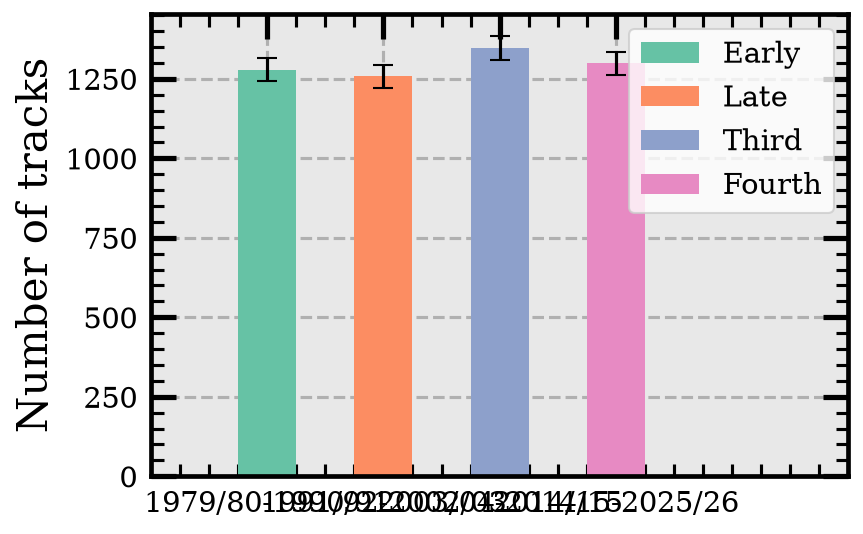

In [157]:
error_early = np.sqrt(len(early_summary))
error_late = np.sqrt(len(late_summary))
error_third = np.sqrt(len(third_summary))
error_fourth = np.sqrt(len(fourth_summary))
fig, ax = plt.subplots(figsize=(6, 4))

ax.bar(1, len(early_summary), width=0.1, color="C0", label="Early")
ax.bar(1.2, len(late_summary), width=0.1, color="C1", label="Late")
ax.errorbar(1, len(early_summary), yerr=error_early, fmt="none", ecolor="k", capsize=5)
ax.errorbar(1.2, len(late_summary), yerr=error_late, fmt="none", ecolor="k", capsize=5)
ax.bar(1.4, len(third_summary), width=0.1, color="C2", label="Third")
ax.bar(1.6, len(fourth_summary), width=0.1, color="C3", label="Fourth")
ax.errorbar(1.4, len(third_summary), yerr=error_third, fmt="none", ecolor="k", capsize=5)
ax.errorbar(1.6, len(fourth_summary), yerr=error_fourth, fmt="none", ecolor="k", capsize=5)
ax.set_xticks([1, 1.2, 1.4, 1.6])
ax.set_xticklabels(["1979/80-1990/91", "1991/92-2002/03", "2003/04-2014/15", "2014/15-2025/26"])
ax.set_xlim(0.8, 2)
ax.set_ylabel("Number of tracks")
ax.legend()

print(len(early_summary)+2*error_early, len(late_summary))


Mean number of storms per season (early): 116.3
Mean number of storms per season (late): 114.4
Mean number of storms per season (third): 122.5
Mean number of storms per season (fourth): 118.1
Standard deviation of number of storms per season (early): 7.6
Standard deviation of number of storms per season (late): 5.0
Standard deviation of number of storms per season (third): 8.7
Standard deviation of number of storms per season (fourth): 6.1


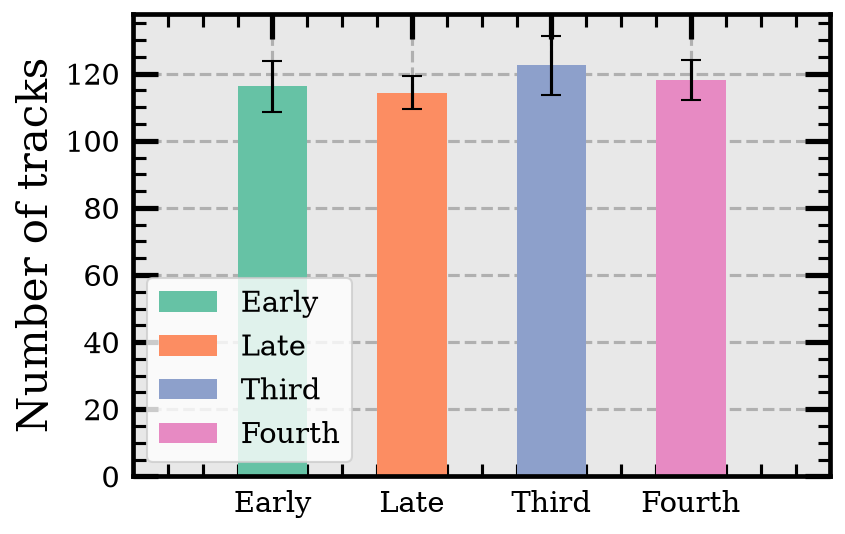

In [158]:
mean_n_storms_early = early_summary.groupby("season")["track_id"].nunique().mean()
mean_n_storms_late = late_summary.groupby("season")["track_id"].nunique().mean()
mean_n_storms_third = third_summary.groupby("season")["track_id"].nunique().mean()
mean_n_storms_fourth = fourth_summary.groupby("season")["track_id"].nunique().mean()

print(f"Mean number of storms per season (early): {mean_n_storms_early:.1f}")
print(f"Mean number of storms per season (late): {mean_n_storms_late:.1f}")
print(f"Mean number of storms per season (third): {mean_n_storms_third:.1f}")
print(f"Mean number of storms per season (fourth): {mean_n_storms_fourth:.1f}")

std_n_storms_early = early_summary.groupby("season")["track_id"].nunique().std()
std_n_storms_late = late_summary.groupby("season")["track_id"].nunique().std()
std_n_storms_third = third_summary.groupby("season")["track_id"].nunique().std()
std_n_storms_fourth = fourth_summary.groupby("season")["track_id"].nunique().std()
print(f"Standard deviation of number of storms per season (early): {std_n_storms_early:.1f}")
print(f"Standard deviation of number of storms per season (late): {std_n_storms_late:.1f}")
print(f"Standard deviation of number of storms per season (third): {std_n_storms_third:.1f}")
print(f"Standard deviation of number of storms per season (fourth): {std_n_storms_fourth:.1f}")

fig, ax = plt.subplots(figsize=(6, 4))

ax.bar(1, mean_n_storms_early, width=0.1, color="C0", label="Early")
ax.bar(1.2, mean_n_storms_late, width=0.1, color="C1", label="Late")
ax.bar(1.4, mean_n_storms_third, width=0.1, color="C2", label="Third")
ax.bar(1.6, mean_n_storms_fourth, width=0.1, color="C3", label="Fourth")
ax.errorbar(1, mean_n_storms_early, yerr=std_n_storms_early, fmt="none", ecolor="k", capsize=5)
ax.errorbar(1.2, mean_n_storms_late, yerr=std_n_storms_late, fmt="none", ecolor="k", capsize=5)
ax.errorbar(1.4, mean_n_storms_third, yerr=std_n_storms_third, fmt="none", ecolor="k", capsize=5)
ax.errorbar(1.6, mean_n_storms_fourth, yerr=std_n_storms_fourth, fmt="none", ecolor="k", capsize=5)

ax.set_xticks([1, 1.2, 1.4, 1.6])
ax.set_xticklabels(["Early", "Late", "Third", "Fourth"])
ax.set_xlim(0.8, 1.8)
ax.set_ylabel("Number of tracks")
ax.legend()



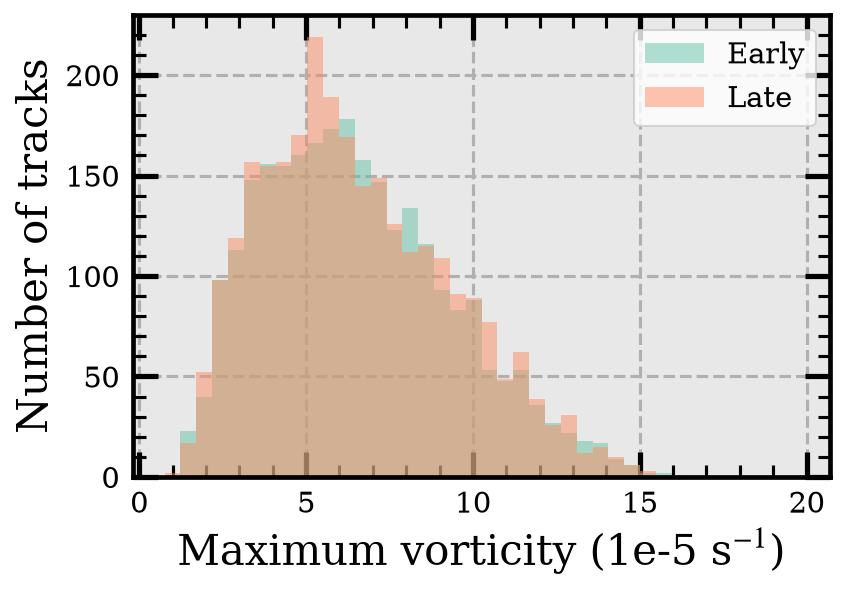

In [139]:
Nbins = 40
x_range = (1, 20)

e_counts, e_edges = np.histogram(early_summary["vo_max_1e5"], bins=Nbins, range=x_range)
l_counts, l_edges = np.histogram(late_summary["vo_max_1e5"], bins=Nbins, range=x_range)

fig, ax = plt.subplots(figsize=(6, 4))

ax.bar(e_edges[:-1], e_counts, width=np.diff(e_edges), color="C0", alpha=0.5, label="Early")
ax.bar(l_edges[:-1], l_counts, width=np.diff(l_edges), color="C1", alpha=0.5, label="Late")
ax.set_xlabel("Maximum vorticity (1e-5 s$^{-1}$)")
ax.set_ylabel("Number of tracks")
ax.legend()


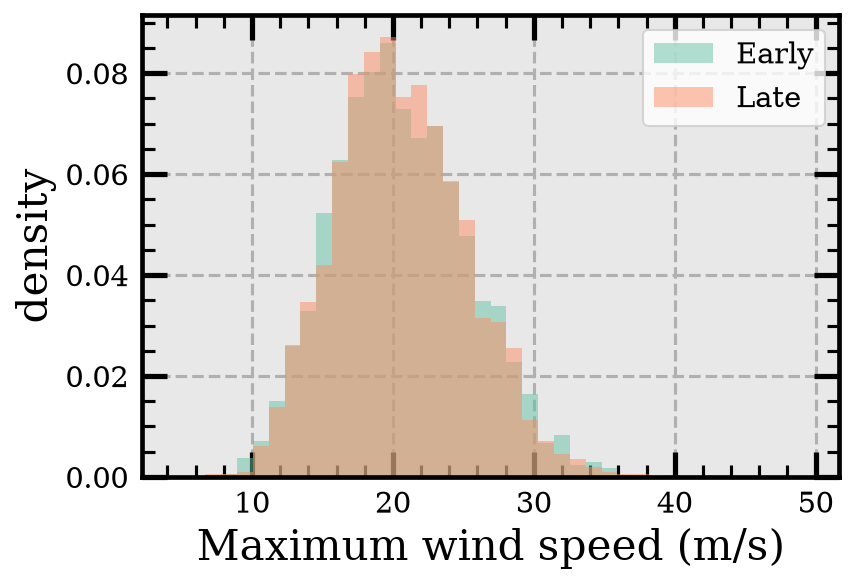

In [140]:
Nbins = 40
x_range = (5, 50)

e_counts, e_edges = np.histogram(early_summary["ws10_max_max"], bins=Nbins, range=x_range, density=True)
l_counts, l_edges = np.histogram(late_summary["ws10_max_max"], bins=Nbins, range=x_range, density=True)

fig, ax = plt.subplots(figsize=(6, 4))

ax.bar(e_edges[:-1], e_counts, width=np.diff(e_edges), color="C0", alpha=0.5, label="Early")
ax.bar(l_edges[:-1], l_counts, width=np.diff(l_edges), color="C1", alpha=0.5, label="Late")
ax.set_xlabel("Maximum wind speed (m/s)")
ax.set_ylabel("density")
ax.legend()

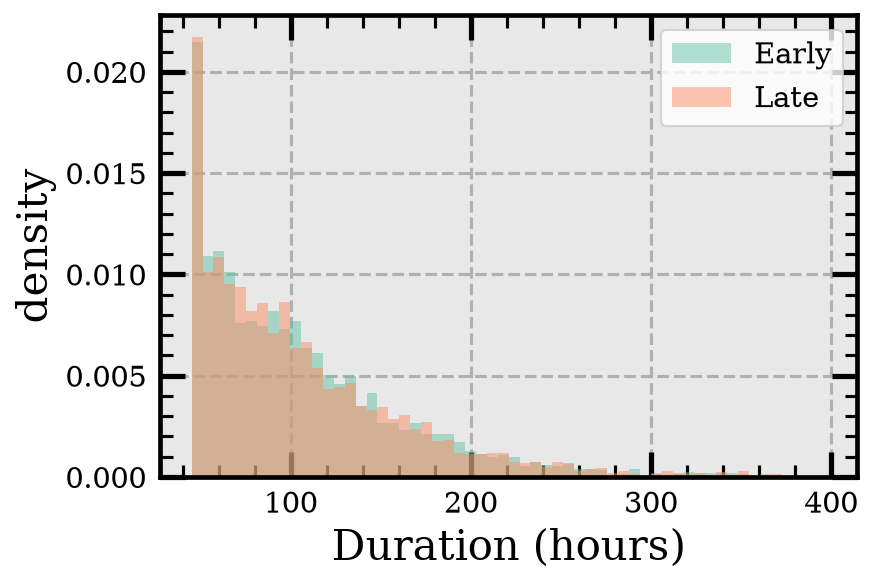

In [141]:
Nbins = 58
x_range = (48, 400)

e_counts, e_edges = np.histogram(early_summary["duration_h"], bins=Nbins, range=x_range, density=True)
l_counts, l_edges = np.histogram(late_summary["duration_h"], bins=Nbins, range=x_range, density=True)

fig, ax = plt.subplots(figsize=(6, 4))

ax.bar(e_edges[:-1], e_counts, width=np.diff(e_edges), color="C0", alpha=0.5, label="Early")
ax.bar(l_edges[:-1], l_counts, width=np.diff(l_edges), color="C1", alpha=0.5, label="Late")
ax.set_xlabel("Duration (hours)")
ax.set_ylabel("density")
ax.legend()

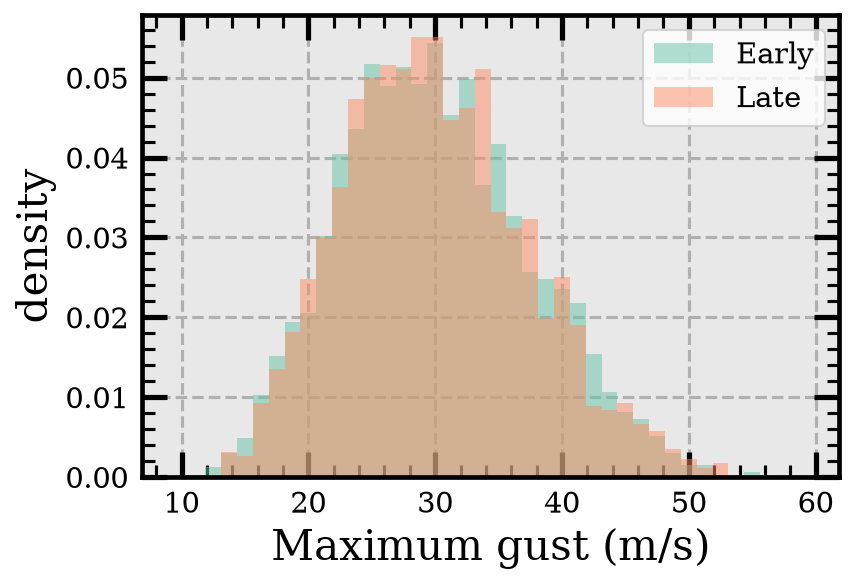

In [142]:
Nbins = 40
x_range = (10, 60)

e_counts, e_edges = np.histogram(early_summary["gust10_max_max"], bins=Nbins, range=x_range, density=True)
l_counts, l_edges = np.histogram(late_summary["gust10_max_max"], bins=Nbins, range=x_range, density=True)

fig, ax = plt.subplots(figsize=(6, 4))

ax.bar(e_edges[:-1], e_counts, width=np.diff(e_edges), color="C0", alpha=0.5, label="Early")
ax.bar(l_edges[:-1], l_counts, width=np.diff(l_edges), color="C1", alpha=0.5, label="Late")
ax.set_xlabel("Maximum gust (m/s)")
ax.set_ylabel("density")
ax.legend()

0        984.497500
1        968.724375
2        978.627500
3       1002.693750
4       1014.941250
           ...     
2642    1001.339375
2643     985.301250
2644    1011.751250
2645     976.637500
2646     964.519375
Name: msl_min_min, Length: 2647, dtype: float64

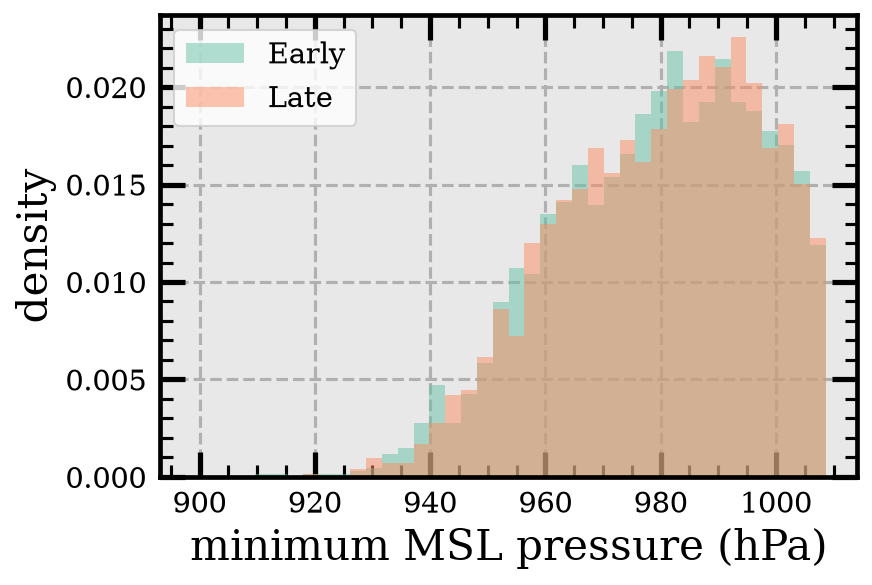

In [143]:
Nbins = 40
x_range = (900, 1010)

e_counts, e_edges = np.histogram(early_summary["msl_min_min"], bins=Nbins, range=x_range, density=True)
l_counts, l_edges = np.histogram(late_summary["msl_min_min"], bins=Nbins, range=x_range, density=True)

fig, ax = plt.subplots(figsize=(6, 4))

ax.bar(e_edges[:-1], e_counts, width=np.diff(e_edges), color="C0", alpha=0.5, label="Early")
ax.bar(l_edges[:-1], l_counts, width=np.diff(l_edges), color="C1", alpha=0.5, label="Late")
ax.set_xlabel("minimum MSL pressure (hPa)")
ax.set_ylabel("density")
ax.legend()

early_summary["msl_min_min"]

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


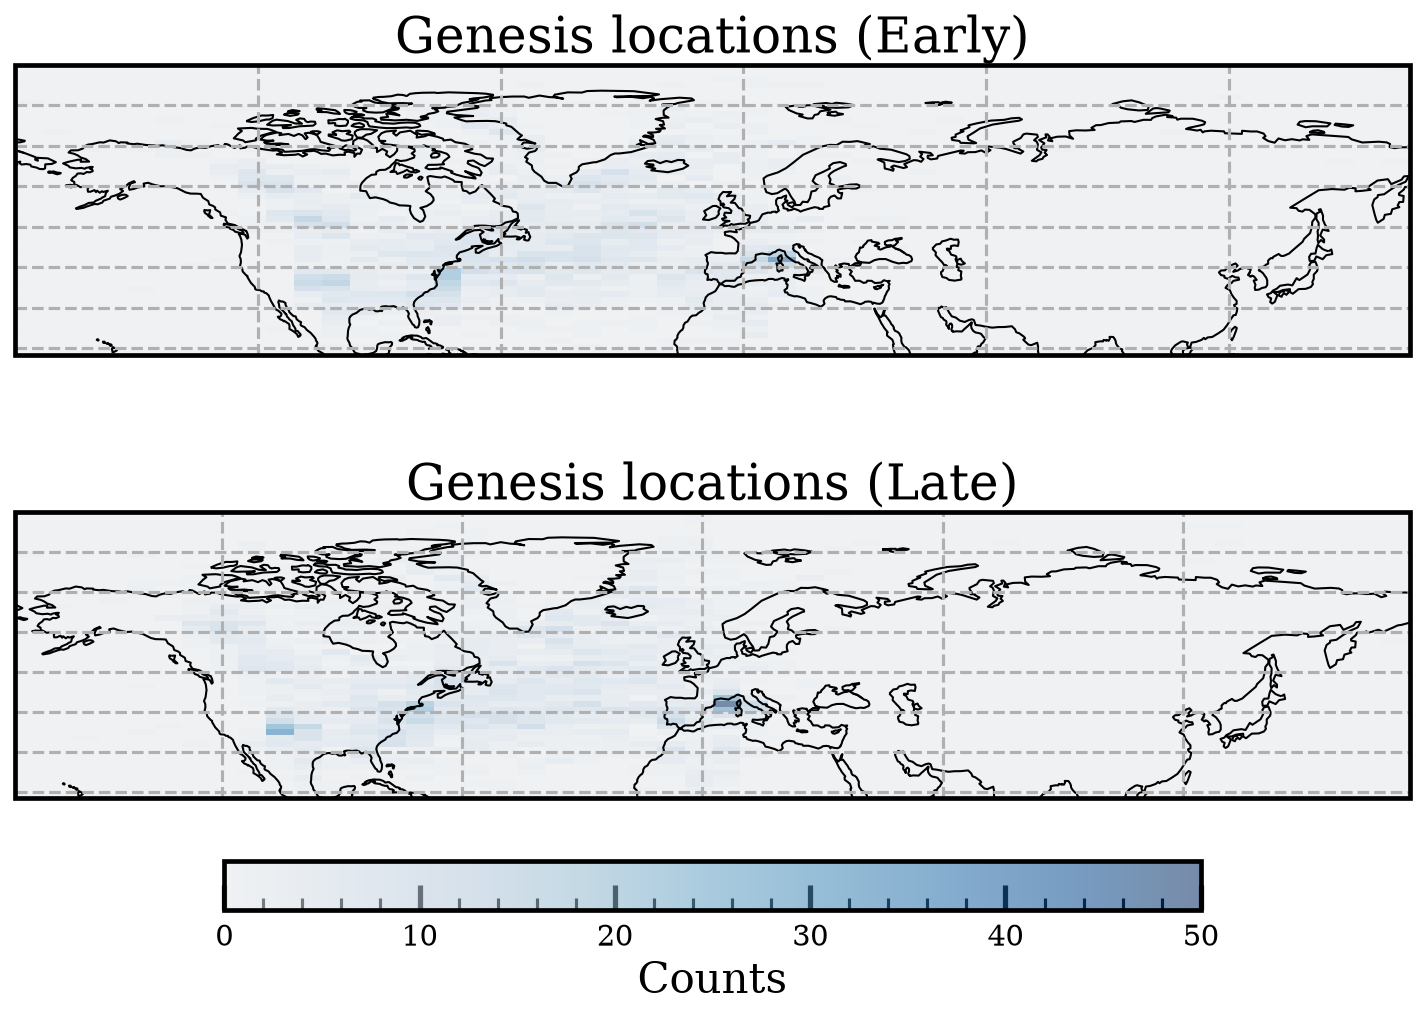

In [144]:
import cartopy.crs as ccrs

vmin = 0
vmax = 50 

counts_early, xedges_early, yedges_early = np.histogram2d(early_summary["lon_genesis"], early_summary["lat_genesis"], bins=50)
counts_late, xedges_late, yedges_late = np.histogram2d(late_summary["lon_genesis"], late_summary["lat_genesis"], bins=50)
counts_diff = counts_late - counts_early

fig, ax = plt.subplots(2,1,figsize=(12, 8), subplot_kw={"projection": ccrs.PlateCarree()})
ax[0].set_title("Genesis locations (Early)")

ax[0].coastlines()
ax[0].gridlines()
ax[0].hist2d(early_summary["lon_genesis"], early_summary["lat_genesis"], bins=50, vmin=vmin, vmax=vmax, cmap="Blues", alpha=0.5, density=False)
#plt.colorbar(label="Counts", ax=ax[0], orientation="horizontal", shrink=0.7)
ax[1].set_title("Genesis locations (Late)")

ax[1].coastlines()
ax[1].gridlines()
C = plt.hist2d(late_summary["lon_genesis"], late_summary["lat_genesis"], bins=50, vmin=vmin, vmax=vmax, cmap="Blues", alpha=0.5, density=False)
plt.colorbar(label="Counts", ax=ax[1], orientation="horizontal", shrink=0.7)




plt.show()



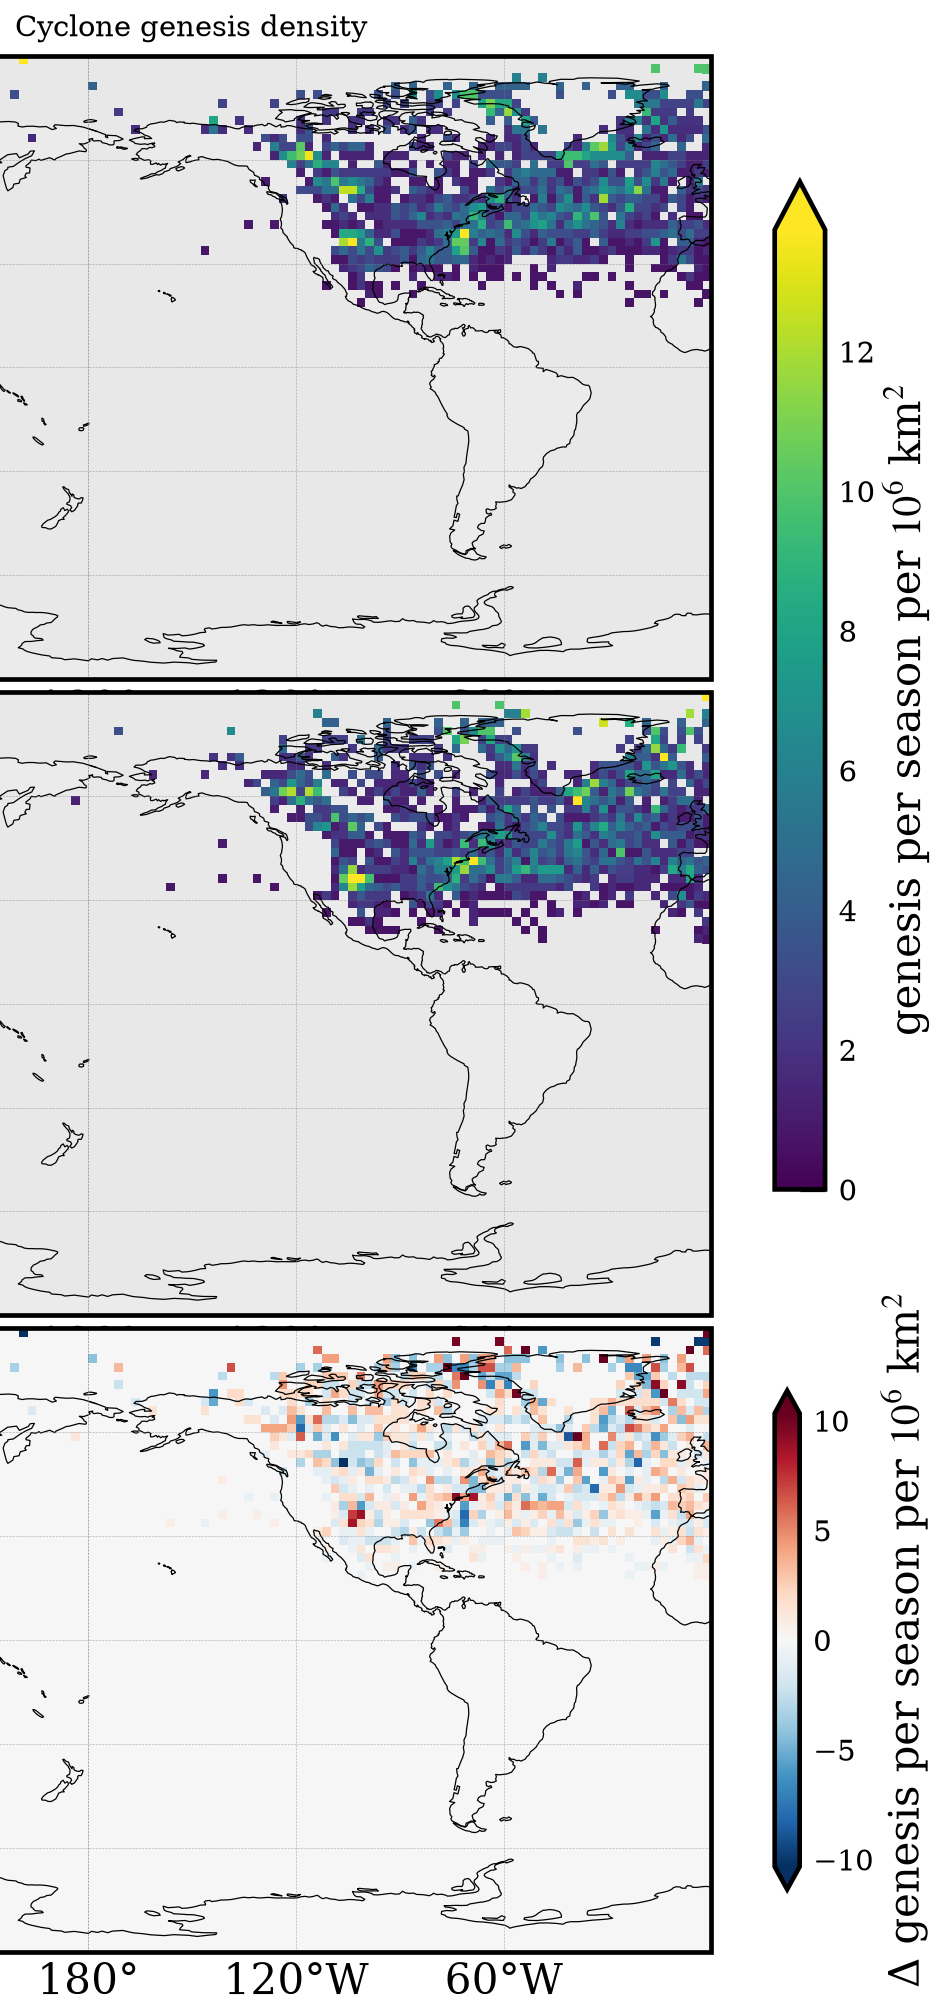

In [145]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ---- settings -------------------------------------------------------------
n_early, n_late = 20, 20      # number of years/seasons in each period, set these
dlon, dlat = 2.5, 2.5         # grid spacing in degrees
lon_edges = np.arange(0, 360 + dlon, dlon)   # TRACK output is usually 0–360
lat_edges = np.arange(-90, 90 + dlat, dlat)

# ---- density on a common grid ---------------------------------------------
R = 6371.0  # km
# area of each lat band's grid box, in units of 10^6 km^2
box_area = (R**2 * np.deg2rad(dlon)
            * np.abs(np.diff(np.sin(np.deg2rad(lat_edges))))) / 1e6   # shape (nlat,)

def genesis_density(df, n_periods):
    H, _, _ = np.histogram2d(df["lon_genesis"] % 360, df["lat_genesis"],
                             bins=[lon_edges, lat_edges])
    H = H.T                                  # -> (lat, lon) for pcolormesh
    return H / n_periods / box_area[:, None] # per season per 10^6 km^2

dens_early = genesis_density(early_summary, n_early)
dens_late  = genesis_density(late_summary,  n_late)
dens_diff  = dens_late - dens_early

# robust colour limits (ignore a few extreme boxes)
both = np.concatenate([dens_early[dens_early > 0], dens_late[dens_late > 0]])
vmax = np.percentile(both, 99)
dmax = np.percentile(np.abs(dens_diff[dens_diff != 0]), 99)

# ---- plot -----------------------------------------------------------------
proj = ccrs.PlateCarree(central_longitude=180)   # use 0 for an Atlantic-centred view
data_crs = ccrs.PlateCarree()

fig, axes = plt.subplots(3, 1, figsize=(10, 13),
                         subplot_kw={"projection": proj}, layout="constrained")

panels = [
    (np.ma.masked_equal(dens_early, 0), f"Early (n = {len(early_summary)})", "viridis", 0, vmax),
    (np.ma.masked_equal(dens_late, 0),  f"Late (n = {len(late_summary)})",   "viridis", 0, vmax),
    (dens_diff, "Late − Early", "RdBu_r", -dmax, dmax),
]

meshes = []
for ax, (field, title, cmap, lo, hi) in zip(axes, panels):
    pm = ax.pcolormesh(lon_edges, lat_edges, field, transform=data_crs,
                       cmap=cmap, vmin=lo, vmax=hi, shading="flat")
    meshes.append(pm)
    ax.add_feature(cfeature.LAND, facecolor="0.92", zorder=0)
    ax.coastlines(linewidth=0.6)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.6)
    gl.top_labels = gl.right_labels = False
    ax.set_title(title, loc="left", fontsize=12)
    # ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=data_crs)  # zoom to your domain

units = r"genesis per season per $10^6$ km$^2$"
fig.colorbar(meshes[0], ax=axes[:2], orientation="vertical", shrink=0.8,
             extend="max", label=units)
fig.colorbar(meshes[2], ax=axes[2], orientation="vertical", shrink=0.8,
             extend="both", label="Δ " + units)

fig.suptitle("Cyclone genesis density", fontsize=14)
plt.show()